# Response and recommendation tags

Distribution of tag combinations, to decide what counts as **valid**.
A combination is valid if all its tags are in the valid set (alone or combined): shades of **green**;
the others are shades of **red** and hatched. Darkest = most frequent; each family shows its
`TOP_N` most frequent combinations and folds the rest into "other valid" / "other invalid".
Models are sorted by valid share (descending) and shown with short labels (`viz/labels.py`).

**All models** = mean over models of each model's share (every model weighs equally, i.e. the average of the
per-model bars), with a 95% hierarchical bootstrap CI: models are resampled, then configurations (a prompt with
its runs) within each model (`tag_stats.model_mean_shares`).

Sample sizes: $N_m$ models, $N_r$ responses. Rule: titles only in PNG; PDFs (paper) have none.

Inputs: `results/responses_metadata/`, `results/recommendations_metadata/` (see `code/scripts/README.md`).
Plots: `results/plots/tags_*`.

In [ ]:
# Setup: make code/libs importable from this notebook, and re-import changed library modules
# automatically (otherwise restart the kernel after editing code/libs)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists()) / 'code' / 'libs'))

from utils import constants as cons
from utils import ios
from responses import tag_stats
from viz import tag_plots
from viz.labels import sample_size_label
from viz.captions import print_caption, tags_figure_caption
from viz.style import apply_style

apply_style()   # scientific-paper style for all figures (viz/style.py)

'Liberation Sans'

In [ ]:
# Parameters
VALID_RESPONSE_TAGS = cons.DEFAULT_VALID_RESPONSE_TAGS   # e.g. correct, wrapped, extra_incomplete, python_literal, embedded
VALID_REC_TAGS = cons.DEFAULT_VALID_REC_TAGS             # e.g. correct, title_removed
TOP_N = cons.TOP_COMBINATIONS_PER_FAMILY
MODELS = None                                            # None = all models
SAVE = True

In [ ]:
# Data (only the columns needed)
summary = ios.load_parquet_folder(cons.DEFAULT_RESPONSES_METADATA_DIR,
                                  columns=tag_stats.RESPONSE_KEY + [cons.COL_RESPONSE_TAGS], models=MODELS)
recommendations = ios.load_parquet_folder(cons.DEFAULT_RECOMMENDATIONS_METADATA_DIR,
                                          columns=tag_stats.RESPONSE_KEY + [cons.COL_REC_TAGS], models=MODELS)
print(f"{len(summary):,} responses | {len(recommendations):,} recommendations | {summary[cons.COL_MODEL].nunique()} models")

928,800 responses | 3,869,884 recommendations | 43 models


## 1. Responses

In [ ]:
response_categories = tag_stats.CombinationCategories.from_combinations(summary[cons.COL_RESPONSE_TAGS], VALID_RESPONSE_TAGS, TOP_N)
response_palette = tag_plots.TagPalette(response_categories)
n_models, n_responses = summary[cons.COL_MODEL].nunique(), len(summary)

### 1a. Per model

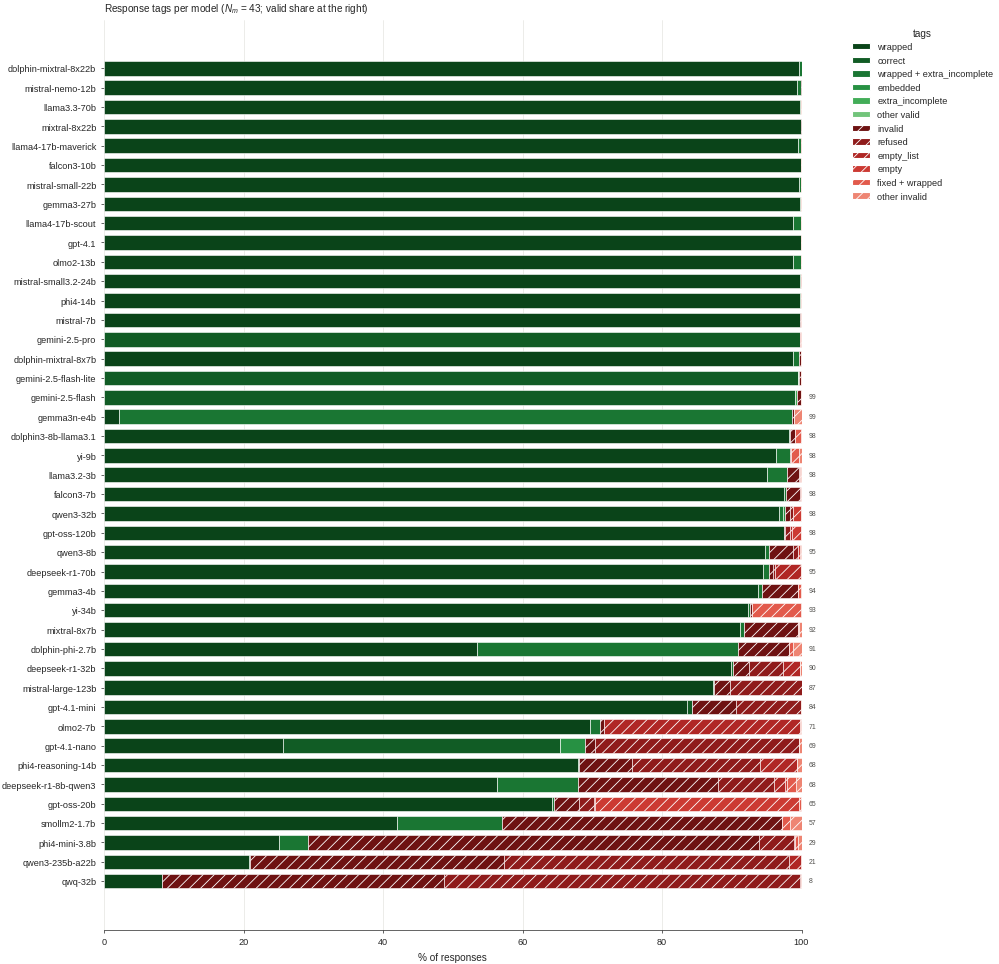

In [ ]:
response_shares = tag_stats.shares_by_group(summary, cons.COL_RESPONSE_TAGS, response_categories)
fig = tag_plots.plot_stacked_shares(response_shares, response_palette, value_label='% of responses',
                                    title=f'Response tags per model ({sample_size_label(n_models)}; valid share at the right)')

### 1b. All models (mean of model shares, 95% CI)

,category,mean,ci_low,ci_high,std_models,n_models,n_rows,is_valid,n,pct
0,wrapped,75.296296,64.870884,85.361453,34.712668,43,928800,True,699352,75.296296
1,correct,7.876507,1.783786,16.624386,26.087730,43,928800,True,73157,7.876507
2,wrapped|extra_incomplete,4.214255,0.712314,9.366298,15.694937,43,928800,True,39142,4.214255
3,embedded,0.091085,0.000646,0.273277,0.536948,43,928800,True,846,0.091085
4,extra_incomplete,0.008290,0.000000,0.023695,0.042726,43,928800,True,77,0.008290
5,other valid,0.002692,0.000000,0.007647,0.012006,43,928800,True,25,0.002692
6,invalid,5.992033,2.517751,10.249257,13.724612,43,928800,False,55654,5.992033
7,refused,4.221038,1.580731,7.628828,10.923063,43,928800,False,39205,4.221038
8,empty_list,1.021964,0.144625,2.409429,4.365399,43,928800,False,9492,1.021964
9,empty,0.761628,0.026214,2.230817,4.475196,43,928800,False,7074,0.761628


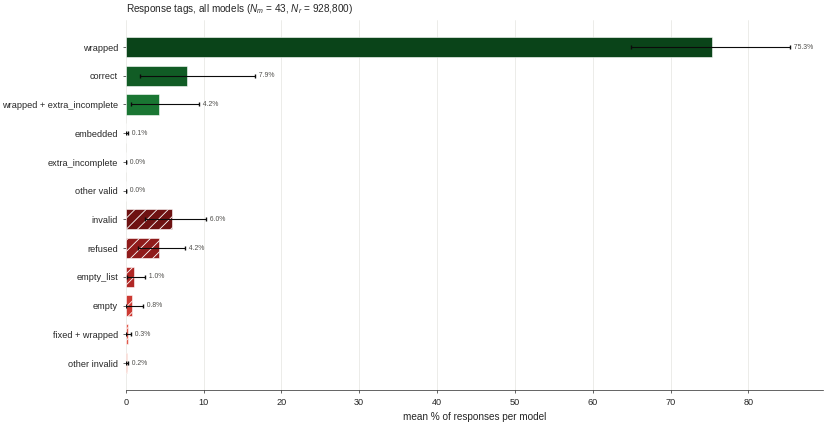

In [ ]:
response_stats = tag_stats.model_mean_shares(summary, cons.COL_RESPONSE_TAGS, response_categories)
fig = tag_plots.plot_overall(response_stats, response_palette, value='mean', value_label='mean % of responses per model',
                             title=f'Response tags, all models ({sample_size_label(n_models, n_responses)})')
response_stats.merge(tag_stats.overall_shares(summary, cons.COL_RESPONSE_TAGS, response_categories)[['category', 'n', 'pct']],
                     on='category')   # pooled counts for reference

### 1c. Paper figure

1a (4/5) and 1b (1/5) in one figure, vertical bars, A4 width. $N_m$ and $N_r$ are annotated inside the
overall panel (no per-model title); titles only in the PNG. Saved as PDF (vector; `cons.PAPER_FIGURE_FORMAT`).

Output format of the LLM responses. Left, share of each model's responses per tag combination ($N_r$
= 928,800 responses from $N_m$ = 43 models); models are sorted by their share of valid responses,
written above each bar when below 100%. Right, mean of the model-level shares (models weighted
equally); error bars, 95% confidence intervals from a hierarchical bootstrap (1,000 replicates;
models resampled, then prompt configurations within models). A response is valid if all its tags are
among correct, wrap, extra_inc, py_lit, embed (green); all other combinations are red and hatched.
Darker shades denote more frequent combinations; the five most frequent combinations of each group
are shown and the rest are pooled as "other valid" and "other invalid". Tags (+, co-occurring tags):
correct, strict JSON array of complete recommendations; embed, JSON surrounded by text; fixed,
output truncated, recovered up to the last complete record; wrap, JSON object wrapping the requested
array; extra_i

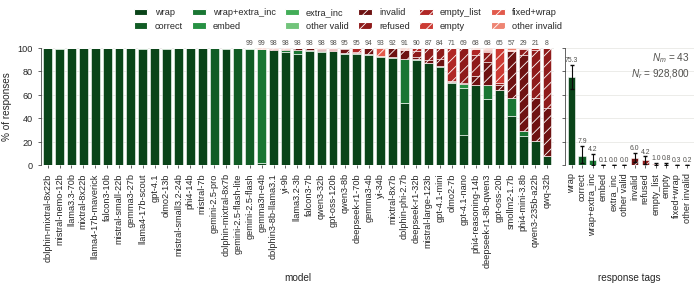

In [ ]:
fig = tag_plots.plot_paper_figure(response_shares, response_stats, response_palette, value='mean',
                                  value_label='% of responses', tags_label='response tags',
                                  annotation=sample_size_label(n_models, n_responses, separator='\n'))
if SAVE: tag_plots.save_figure(fig, f'{cons.PREFIX_PLOT_TAGS}_responses_paper', formats=cons.PAPER_FIGURE_FORMAT)
print_caption(tags_figure_caption('responses', response_categories, VALID_RESPONSE_TAGS,
                                  n_models=n_models, n_responses=n_responses, n_units=n_responses))

## 2. Recommendations

In [ ]:
rec_categories = tag_stats.CombinationCategories.from_combinations(recommendations[cons.COL_REC_TAGS], VALID_REC_TAGS, TOP_N)
rec_palette = tag_plots.TagPalette(rec_categories)
rec_n_models = recommendations[cons.COL_MODEL].nunique()
rec_n_responses = len(recommendations[tag_stats.RESPONSE_KEY].drop_duplicates())   # responses with recommendations

### 2a. Per model

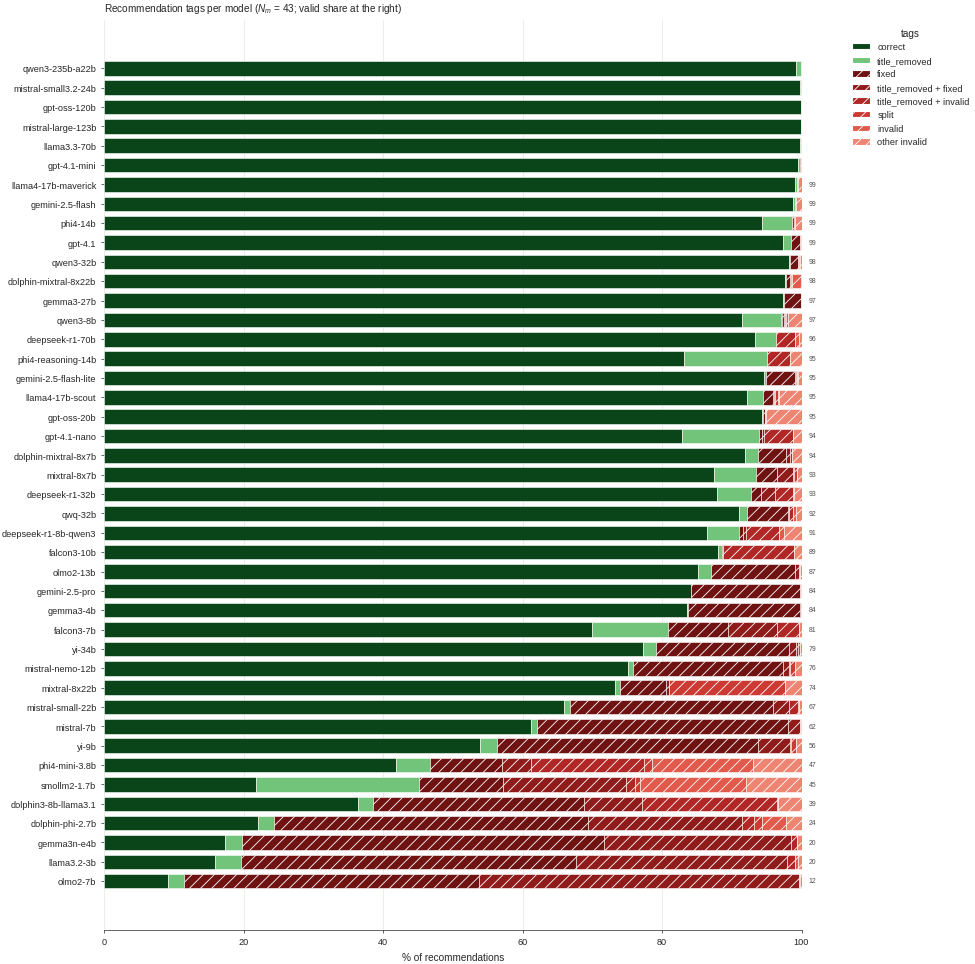

In [ ]:
rec_shares = tag_stats.shares_by_group(recommendations, cons.COL_REC_TAGS, rec_categories)
fig = tag_plots.plot_stacked_shares(rec_shares, rec_palette, value_label='% of recommendations',
                                    title=f'Recommendation tags per model ({sample_size_label(rec_n_models)}; valid share at the right)')

### 2b. All models (mean of model shares, 95% CI)

$N_r$ = responses with recommendations.

,category,mean,ci_low,ci_high,std_models,n_models,n_rows,is_valid
0,correct,77.669132,69.534215,85.095523,26.847135,43,3869884,True
1,title_removed,2.848647,1.721817,4.294072,4.406068,43,3869884,True
2,fixed,10.908881,6.952120,15.613990,15.503309,43,3869884,False
3,title_removed|fixed,4.185685,1.839492,7.271221,9.712257,43,3869884,False
4,title_removed|invalid,1.751690,0.759176,2.995474,4.059233,43,3869884,False
5,split,0.547856,0.090754,1.394787,2.533426,43,3869884,False
6,invalid,0.883625,0.117155,1.981766,3.162018,43,3869884,False
7,other invalid,1.204483,0.719059,1.779071,1.769519,43,3869884,False


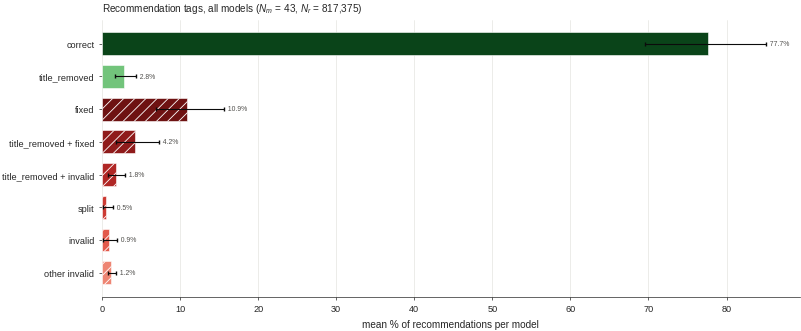

In [ ]:
rec_stats = tag_stats.model_mean_shares(recommendations, cons.COL_REC_TAGS, rec_categories)
fig = tag_plots.plot_overall(rec_stats, rec_palette, value='mean', value_label='mean % of recommendations per model',
                             title=f'Recommendation tags, all models ({sample_size_label(rec_n_models, rec_n_responses)})')
rec_stats

### 2c. Paper figure

2a (4/5) and 2b (1/5) in one figure; models sorted by % valid recommendations (correct + title_removed).
$N_m$ and $N_r$ are annotated inside the overall panel; titles only in the PNG.

Name quality of the recommended scholars. Left, share of each model's recommendations per tag
combination ($N_{rec}$ = 3,869,884 recommendations in the $N_r$ = 817,375 responses that contain
recommendations, from $N_m$ = 43 models); models are sorted by their share of valid recommendations,
written above each bar when below 100%. Right, mean of the model-level shares (models weighted
equally); error bars, 95% confidence intervals from a hierarchical bootstrap (1,000 replicates;
models resampled, then prompt configurations within models). A recommendation is valid if all its
tags are among correct, title_rm (green); all other combinations are red and hatched. Darker shades
denote more frequent combinations; the five most frequent combinations of each group are shown and
the rest are pooled as "other valid" and "other invalid". Tags (+, co-occurring tags): correct,
first and last name given as requested; title_rm, academic or honorific title removed (e.g. Dr.,
Prof.); fixed, one name par

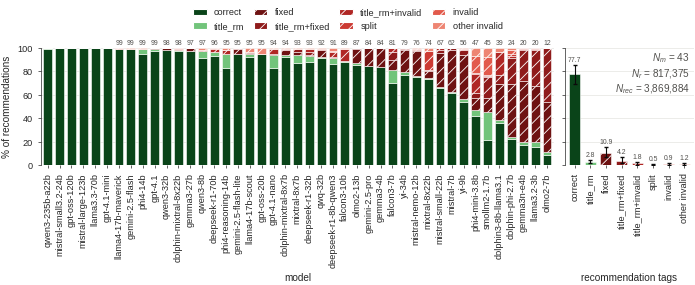

In [ ]:
fig = tag_plots.plot_paper_figure(rec_shares, rec_stats, rec_palette, value='mean',
                                  value_label='% of recommendations', tags_label='recommendation tags',
                                  annotation=sample_size_label(rec_n_models, rec_n_responses, len(recommendations),
                                                               separator='\n'))
if SAVE: tag_plots.save_figure(fig, f'{cons.PREFIX_PLOT_TAGS}_recommendations_paper', formats=cons.PAPER_FIGURE_FORMAT)
print_caption(tags_figure_caption('recommendations', rec_categories, VALID_REC_TAGS,
                                  n_models=rec_n_models, n_responses=rec_n_responses, n_units=len(recommendations)))